# Notebook 01 — Reproducción de la simulación de Sigrist (2021)

Este notebook reproduce el ejemplo simulado usado por Sigrist (2021) en *Tree-Boosting for Spatial Data*. El objetivo es verificar el comportamiento básico de GPBoost en un caso controlado, donde la variable respuesta se construye como:

\[
y = F(x_1) + b(s) + \varepsilon
\]

Aquí, \(F(x_1)\) representa un efecto fijo no lineal, \(b(s)\) un proceso espacial gaussiano con covarianza exponencial y \(\varepsilon\) un término de error independiente. El flujo incluye la carga de datos simulados, el entrenamiento de GPBoost, la predicción sobre una rejilla espacial, la comparación con métodos alternativos y una lectura básica mediante valores SHAP.

## Compatibilidad con Google Colab

La siguiente celda detecta si el notebook se ejecuta en Google Colab. En ese caso, instala las dependencias necesarias y clona el repositorio para acceder a los datos, modelos y carpetas de salida. En ejecución local, el notebook asume que se está trabajando desde la raíz del repositorio o desde la carpeta `notebooks/`.

In [1]:
from pathlib import Path
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/linaq11/examen-2-gpboost.git"
REPO_DIR = Path("/content/repo")

if IN_COLAB:
    print("Entorno Colab detectado. Instalando dependencias...")
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "gpboost", "shap"],
        check=True,
    )

    if not REPO_DIR.exists():
        subprocess.run(
            ["git", "clone", "-q", REPO_URL, str(REPO_DIR)],
            check=True,
        )

    os.chdir(REPO_DIR)
else:
    current_dir = Path.cwd()

    # Si el notebook se ejecuta desde repo/notebooks/, se sube a la raíz del repo.
    if current_dir.name == "notebooks":
        os.chdir(current_dir.parent)

print(f"Directorio de trabajo: {Path.cwd()}")

Directorio de trabajo: /sessions/optimistic-lucid-ptolemy/mnt/PERCEPCION REMOTA/Examen_2_GPBoost


## 1. Configuración general

In [2]:
from pathlib import Path

import gpboost as gpb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import RandomForestRegressor

RANDOM_SEED = 1
np.random.seed(RANDOM_SEED)

DATA_DIR = Path("data")
MODEL_DIR = Path("modelos")
FIGURE_DIR = Path("figuras")

for directory in (DATA_DIR, MODEL_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

/sessions/optimistic-lucid-ptolemy/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Carga de los datos simulados

Los datos de entrenamiento se generaron previamente con semilla fija (`np.random.seed(1)`) siguiendo la estructura del ejemplo original. Se cargan desde `data/simulado_train_seed1.csv` para mantener el notebook reproducible sin regenerar la simulación en cada ejecución.

In [3]:
train_path = DATA_DIR / "simulado_train_seed1.csv"
df_train = pd.read_csv(train_path)

X = df_train[["X1", "X2"]].to_numpy()
y = df_train["y"].to_numpy()
coords = df_train[["s_1", "s_2"]].to_numpy()
n_obs = len(df_train)

print(f"Observaciones: {n_obs}")
print(f"Matriz X: {X.shape}")
print(f"Coordenadas espaciales: {coords.shape}")

df_train.head()

Observaciones: 200
Matriz X: (200, 2)
Coordenadas espaciales: (200, 2)


,s_1,s_2,X1,X2,y,b
0,0.208511,0.360162,0.192012,0.591628,-0.560123,0.135133
1,0.000114,0.302333,0.606831,0.441844,0.122993,0.053007
2,0.146756,0.092339,0.864551,0.543482,2.363380,0.503057
3,0.186260,0.345561,0.492730,0.418126,-2.651826,0.914670
4,0.396767,0.538817,0.062225,0.362149,-1.733311,-0.021206


## 3. Visualización inicial de la simulación

Se representan tres componentes del conjunto simulado: la función no lineal \(F(x_1)\), el campo espacial verdadero \(b(s)\) y las observaciones \(y\) sobre el plano espacial.

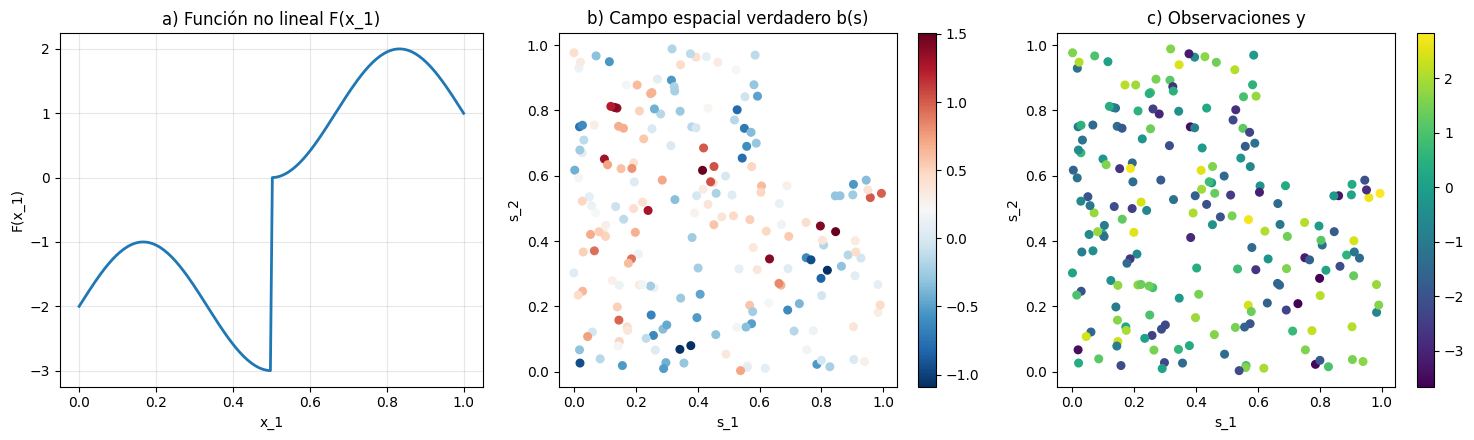

In [4]:
def fixed_effect_function(x):
    """Evaluate the fixed-effect function used in the simulation.

    The function combines a sinusoidal component with a discontinuity at x = 0.5.
    This explicit implementation avoids numerical instability around the
    discontinuity and keeps the simulated mechanism readable.
    """
    x = np.asarray(x, dtype=float)
    step = np.where(x > 0.5, 1.0, 0.0)
    return np.sin(3 * np.pi * x) + (1 + 3 * step) - 3


xx = np.linspace(0, 1, 200)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].plot(xx, fixed_effect_function(xx), linewidth=2)
axes[0].set_xlabel("x_1")
axes[0].set_ylabel("F(x_1)")
axes[0].set_title("a) Función no lineal F(x_1)")
axes[0].grid(alpha=0.3)

spatial_field = axes[1].scatter(
    coords[:, 0],
    coords[:, 1],
    c=df_train["b"].to_numpy(),
    cmap="RdBu_r",
    s=30,
)
plt.colorbar(spatial_field, ax=axes[1])
axes[1].set_xlabel("s_1")
axes[1].set_ylabel("s_2")
axes[1].set_title("b) Campo espacial verdadero b(s)")

observations = axes[2].scatter(
    coords[:, 0],
    coords[:, 1],
    c=y,
    cmap="viridis",
    s=30,
)
plt.colorbar(observations, ax=axes[2])
axes[2].set_xlabel("s_1")
axes[2].set_ylabel("s_2")
axes[2].set_title("c) Observaciones y")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig1_datos_simulados.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Entrenamiento de GPBoost

Se entrena un modelo GPBoost con covarianza exponencial para el componente espacial. Los hiperparámetros siguen el ejemplo de referencia: `learning_rate=0.01`, `max_depth=3`, `min_data_in_leaf=10`, `num_leaves=1024` y 247 iteraciones de boosting.

In [5]:
gp_model = gpb.GPModel(gp_coords=coords, cov_function="exponential")

params = {
    "objective": "regression_l2",
    "learning_rate": 0.01,
    "max_depth": 3,
    "min_data_in_leaf": 10,
    "num_leaves": 1024,
    "verbose": -1,
}

train_data = gpb.Dataset(X, y)

bst = gpb.train(
    params=params,
    train_set=train_data,
    gp_model=gp_model,
    num_boost_round=247,
)

model_path = MODEL_DIR / "gpboost_basico.json"
bst.save_model(model_path)

print(f"Modelo guardado en: {model_path}")

Modelo guardado en: modelos/gpboost_basico.json


## 5. Predicción sobre una rejilla espacial de 50 × 50

In [6]:
grid_size = 50

s1_grid = np.linspace(0, 1, grid_size)
s2_grid = np.linspace(0, 1, grid_size)
S1, S2 = np.meshgrid(s1_grid, s2_grid)

coords_test = np.column_stack([S1.ravel(), S2.ravel()])

# Para visualizar el componente fijo sobre la rejilla, se genera una secuencia
# reproducible de covariables. La evaluación directa de F(x_1) se realiza abajo
# sobre una curva independiente.
X_test = np.column_stack(
    [
        np.linspace(0, 1, grid_size * grid_size),
        np.linspace(0, 1, grid_size * grid_size),
    ]
)

pred = bst.predict(
    data=X_test,
    gp_coords_pred=coords_test,
    pred_latent=True,
    predict_var=True,
)

fixed_effect_pred = np.asarray(pred["fixed_effect"]).reshape(grid_size, grid_size)
spatial_effect_pred = np.asarray(pred["random_effect_mean"]).reshape(grid_size, grid_size)
spatial_effect_var = np.asarray(pred["random_effect_cov"]).reshape(grid_size, grid_size)

La siguiente figura compara el campo espacial predicho, la incertidumbre posterior del componente espacial, la forma estimada de \(F(x_1)\) y el campo espacial verdadero usado como referencia.

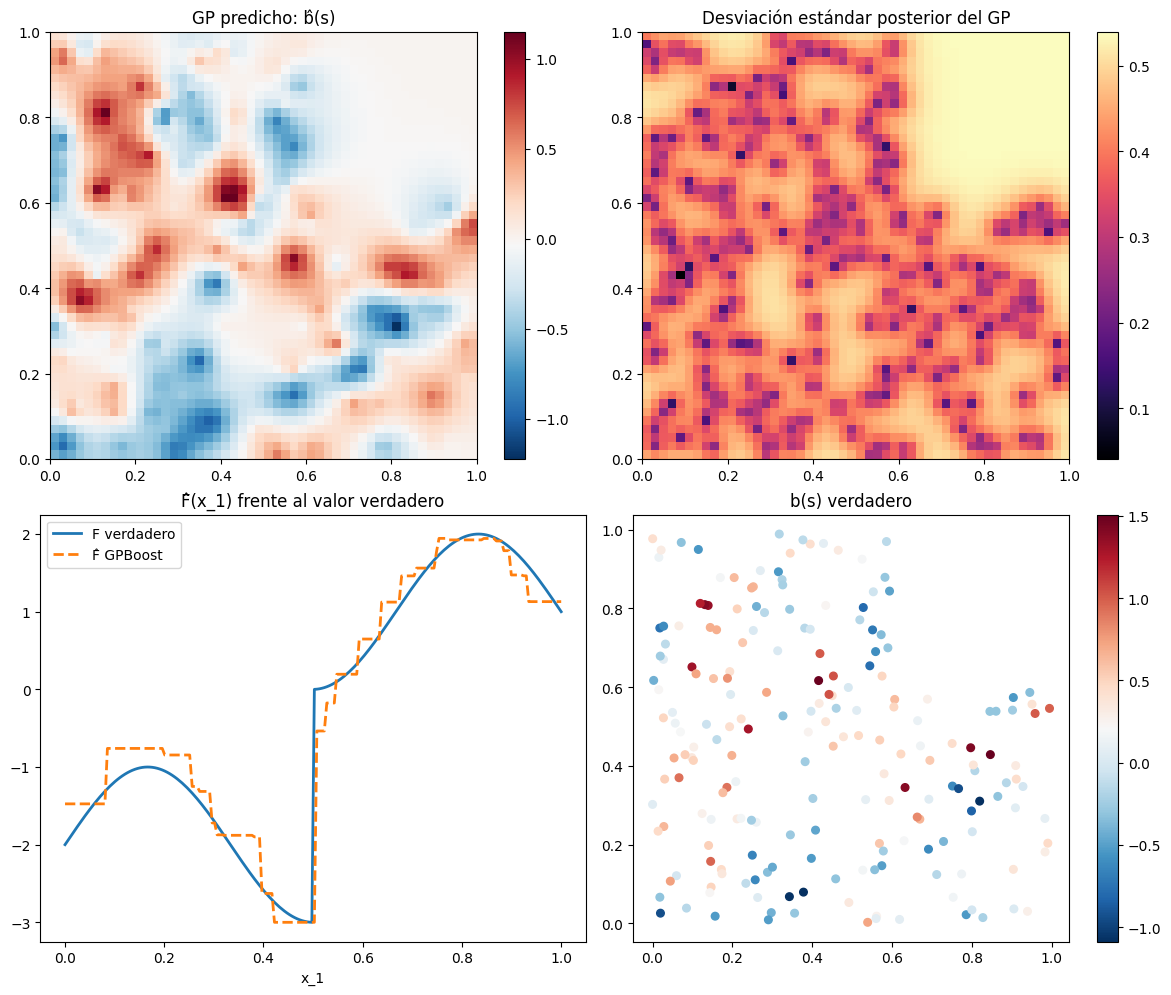

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

ax = axes[0, 0]
image = ax.imshow(
    spatial_effect_pred,
    origin="lower",
    extent=[0, 1, 0, 1],
    cmap="RdBu_r",
)
plt.colorbar(image, ax=ax)
ax.set_title("GP predicho: b̂(s)")

ax = axes[0, 1]
image = ax.imshow(
    np.sqrt(spatial_effect_var),
    origin="lower",
    extent=[0, 1, 0, 1],
    cmap="magma",
)
plt.colorbar(image, ax=ax)
ax.set_title("Desviación estándar posterior del GP")

ax = axes[1, 0]
x_curve = np.linspace(0, 1, 200)
X_curve = np.column_stack([x_curve, np.full_like(x_curve, 0.5)])
fixed_effect_curve = np.asarray(
    bst.predict(
        data=X_curve,
        pred_latent=True,
        ignore_gp_model=True,
    )
).ravel()

ax.plot(x_curve, fixed_effect_function(x_curve), linewidth=2, label="F verdadero")
ax.plot(x_curve, fixed_effect_curve, linestyle="--", linewidth=2, label="F̂ GPBoost")
ax.set_xlabel("x_1")
ax.set_title("F̂(x_1) frente al valor verdadero")
ax.legend()

ax = axes[1, 1]
reference = ax.scatter(
    coords[:, 0],
    coords[:, 1],
    c=df_train["b"].to_numpy(),
    cmap="RdBu_r",
    s=30,
)
plt.colorbar(reference, ax=ax)
ax.set_title("b(s) verdadero")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig2_predicciones_gpboost.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Comparación con métodos alternativos

La comparación se basa en una tabla ya derivada para el mismo escenario de simulación. Se contrasta GPBoost con tres alternativas: Linear GP, L2Boost y Random Forest con coordenadas espaciales como predictores.

In [8]:
comparison_path = DATA_DIR / "tabla_comparativa_metodos.csv"
comparison_table = pd.read_csv(comparison_path)

comparison_table

,Método,RMSE
0,GPBoost (boosting + GP),0.6073
1,Linear GP (universal kriging),1.0915
2,L2Boost (boosting + coords),0.6500
3,Random Forest + coords,0.6905


### Lectura de resultados

GPBoost obtiene el menor RMSE dentro de los métodos evaluados. El Linear GP queda rezagado porque su componente fijo lineal no puede representar adecuadamente la discontinuidad de \(F(x_1)\). L2Boost y Random Forest reducen el error al incorporar las coordenadas como predictores, pero ese procedimiento no equivale a modelar de forma explícita la dependencia espacial mediante un proceso gaussiano.

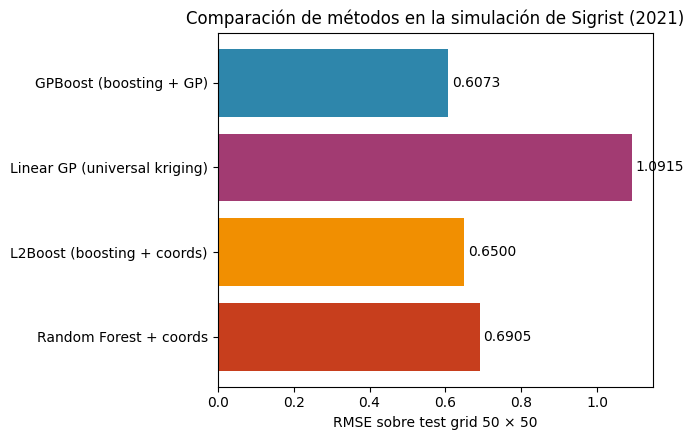

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.barh(
    comparison_table["Método"],
    comparison_table["RMSE"],
    color=["#2E86AB", "#A23B72", "#F18F01", "#C73E1D"],
)

for index, rmse in enumerate(comparison_table["RMSE"]):
    ax.text(rmse + 0.01, index, f"{rmse:.4f}", va="center")

ax.set_xlabel("RMSE sobre test grid 50 × 50")
ax.set_title("Comparación de métodos en la simulación de Sigrist (2021)")
ax.invert_yaxis()

plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig3_comparativa_metodos.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Interpretación con valores SHAP

Los valores SHAP se calculan sobre el booster, es decir, sobre el componente fijo del modelo. Dado que la señal no lineal fue construida únicamente a partir de \(X_1\), se espera que \(X_2\) tenga una contribución marginal baja.

/sessions/optimistic-lucid-ptolemy/tmp/ipykernel_6/3330727319.py:4: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


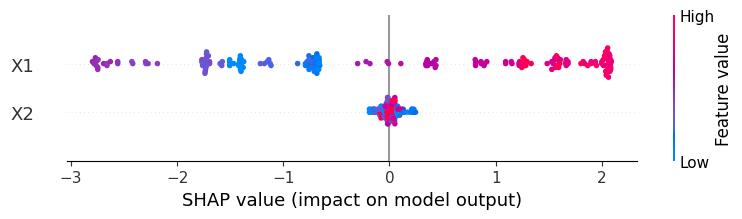

In [10]:
explainer = shap.TreeExplainer(bst)
shap_values = explainer.shap_values(X)

shap.summary_plot(
    shap_values,
    X,
    feature_names=["X1", "X2"],
    show=False,
)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig4_shap_values.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusión

El ejemplo de Sigrist (2021) se reproduce de forma satisfactoria. GPBoost recupera la estructura general de \(F(x_1)\), predice el componente espacial \(b(s)\) y mantiene el mejor desempeño comparativo según RMSE. La lectura mediante SHAP es coherente con el diseño de la simulación, ya que concentra la mayor parte de la contribución en \(X_1\).